In [1]:
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import random
import time
import numpy as np
import torch
import torch.nn.functional as F
import torch.optim as optim
import torch.nn as nn

In [23]:
def assign_label(flower_type):
    if flower_type == 'daisy':
        return 1
    elif flower_type == 'dandelion':
        return 2
    elif flower_type == 'rose':
        return 3
    elif flower_type == 'sunflower':
        return 4
    elif flower_type == 'tulip':   
        return 0


In [21]:
classes = ['tulip', 'daisy', 'dandelion', 'rose', 'sunflower']

X = []
Z = []

inputdataset = r"C:\Users\DIVYANSH DESHMUKH\Desktop\Semester\Seventh Semester\Deep Learning\DL\flowers"

for flower in os.listdir(inputdataset):
    flower_path = os.path.join(inputdataset, flower)  

    if not os.path.isdir(flower_path):  
        continue

    for filename in os.listdir(flower_path):
        img_path = os.path.join(flower_path, filename)  
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)

        if img is None:
            print(f"Warning: {img_path} could not be loaded.")
            continue
        img = cv2.resize(img, (224, 224))
        label = assign_label(flower)
        X.append(img / 255.0)
        Z.append(label)

In [22]:
X = np.array(X)
Z = np.array(Z, dtype=np.int32)
X = torch.from_numpy(X)
Z = torch.from_numpy(Z).long()
Y = F.one_hot(Z, num_classes=5)

print(f"Shape of X: {X.shape}")
print(f"Shape of Z: {Z.shape}")
print(f"Shape of Y: {Y.shape}")


MemoryError: Unable to allocate 4.84 GiB for an array with shape (4317, 224, 224, 3) and data type float64

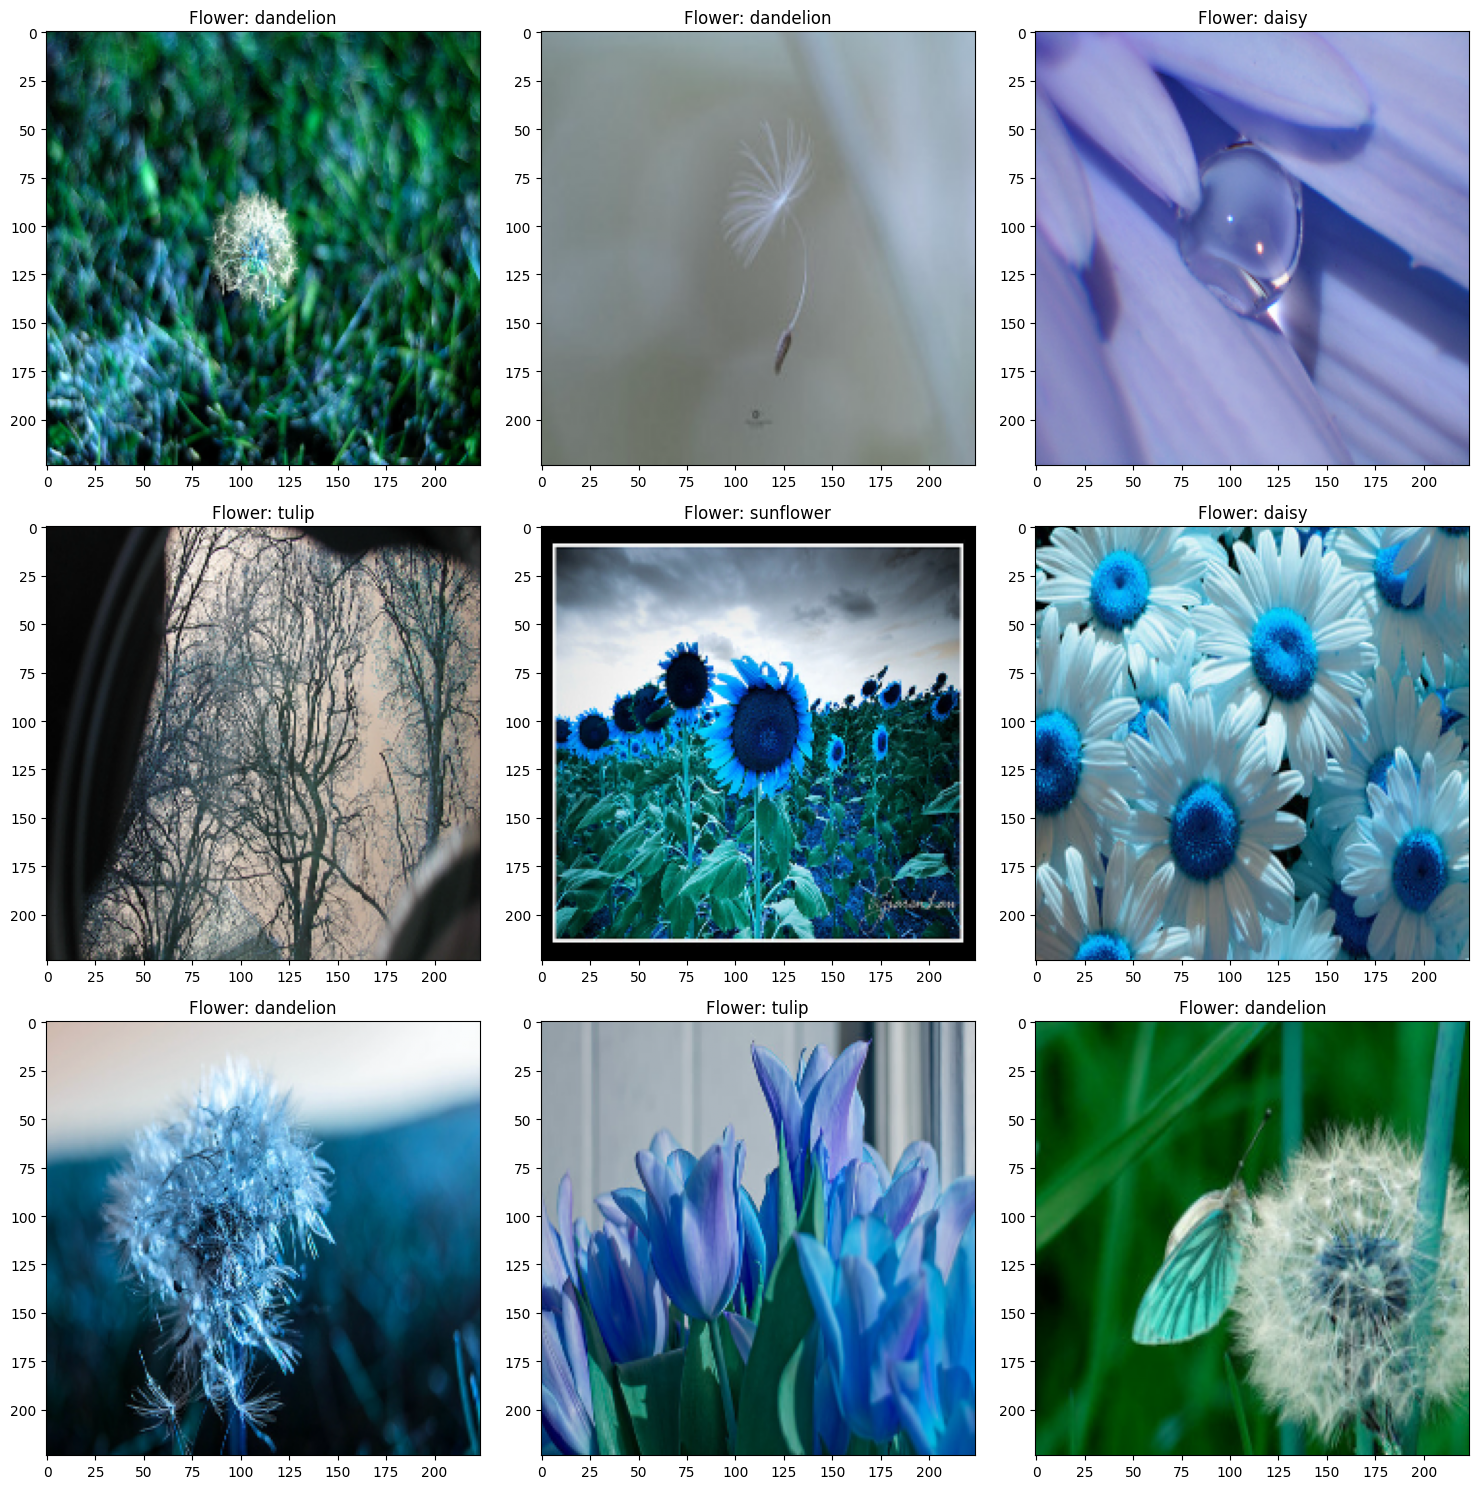

In [8]:
figure, axes = plt.subplots(3, 3)
figure.set_size_inches(15, 15)

for row in range(3):
    for col in range(3):
        index = random.randint(0, len(X) - 1)

        image = X[index]
        flower_label = Z[index]

        axes[row, col].imshow(image)
        axes[row, col].set_title(f"Flower: {classes[flower_label]}")

plt.tight_layout()
plt.show()

In [9]:
indices = np.arange(len(X))
np.random.shuffle(indices)

train_indices = indices[:500]
test_indices = indices[500:750]

X_train = X[train_indices]
Y_train = Y[train_indices]
X_test = X[test_indices]
Y_test = Y[test_indices]

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of Y_train: {Y_train.shape}")
print(f"Shape of Y_test: {Y_test.shape}")

Shape of X_train: torch.Size([500, 224, 224, 3])
Shape of X_test: torch.Size([250, 224, 224, 3])
Shape of Y_train: torch.Size([500, 5])
Shape of Y_test: torch.Size([250, 5])


In [13]:
# Define the model
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(128 * 26 * 26, 128)  # Adjust the input size based on the output of the conv layers
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.softmax(self.fc2(x), dim=1)
        return x

# Instantiate the model, define the loss function and the optimizer
model = CNNModel().float()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training parameters
epochs = 10
batch_size = 32

# Assuming X_train, Y_train, X_test, Y_test are already defined as PyTorch tensors
train_loader = torch.utils.data.DataLoader(dataset=torch.utils.data.TensorDataset(X_train, Y_train), batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=torch.utils.data.TensorDataset(X_test, Y_test), batch_size=batch_size, shuffle=False)

# Train the model with time estimation
start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    model.train()
    
    for i, (inputs, labels) in enumerate(train_loader):
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
    
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for inputs, labels in test_loader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    epoch_end_time = time.time()
    elapsed_time = epoch_end_time - start_time
    avg_epoch_time = elapsed_time / (epoch + 1)
    remaining_time = avg_epoch_time * (epochs - epoch - 1)
    
    print(f"Epoch {epoch + 1}/{epochs} completed in {epoch_end_time - epoch_start_time:.2f} seconds.")
    print(f"Estimated remaining time: {remaining_time:.2f} seconds.")
    print(f"Accuracy on test set: {100 * correct / total:.2f}%")

total_time = time.time() - start_time
print(f"Total training time: {total_time:.2f} seconds.")

RuntimeError: Input type (double) and bias type (float) should be the same

In [21]:
# Define the model
model = Sequential()

# Add convolutional layers
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten the layers
model.add(Flatten())

# Add fully connected layers
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(5, activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model with time estimation
epochs = 10
batch_size = 32
start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    model.fit(X_train, Y_train, epochs=1, batch_size=batch_size, validation_data=(X_test, Y_test))
    epoch_end_time = time.time()
    
    elapsed_time = epoch_end_time - start_time
    avg_epoch_time = elapsed_time / (epoch + 1)
    remaining_time = avg_epoch_time * (epochs - epoch - 1)
    
    print(f"Epoch {epoch + 1}/{epochs} completed in {epoch_end_time - epoch_start_time:.2f} seconds.")
    print(f"Estimated remaining time: {remaining_time:.2f} seconds.")

total_time = time.time() - start_time
print(f"Total training time: {total_time:.2f} seconds.")

c:\Users\DIVYANSH DESHMUKH\AppData\Local\Programs\Python\Python39\lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 15s 782ms/step - accuracy: 0.2167 - loss: 2.3731 - val_accuracy: 0.3440 - val_loss: 1.4975
Epoch 1/10 completed in 17.74 seconds.
Estimated remaining time: 159.69 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 662ms/step - accuracy: 0.3164 - loss: 1.4968 - val_accuracy: 0.4840 - val_loss: 1.2985
Epoch 2/10 completed in 13.25 seconds.
Estimated remaining time: 123.98 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 656ms/step - accuracy: 0.4210 - loss: 1.3565 - val_accuracy: 0.4280 - val_loss: 1.1990
Epoch 3/10 completed in 10.91 seconds.
Estimated remaining time: 97.79 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 650ms/step - accuracy: 0.4609 - loss: 1.2681 - val_accuracy: 0.5240 - val_loss: 1.1048
Epoch 4/10 completed in 10.82 seconds.
Estimated remaining time: 79.09 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 671ms/step - accuracy: 0.5186 - loss: 1.1997 - val_accuracy: 0.5520 - val_loss: 1.0953
Epoch 5/10 completed in 11.10 seconds.
Estimated remaining time: 63.83 seconds.
16/16 ━━